# Pushing the Score

Reads `long_dataframe_2009_to_2026.pkl` (from `build_long_dataframe.ipynb`) and tests how far the score can go with more years, more features, warning signs from the filings and an ensemble of models.

**The test: walk forward by year.** For each test year, the model is trained only on reports whose answer was already known when that year started: a report's answer (bankrupt within 365 days or not) is known 365 days after it is filed, so a model for 2020 trains on reports filed up to the end of 2018. Then it scores every report filed in 2020. To save time, one model scores two test years: the model trained up to 2018 scores 2020 and 2021 (for 2021 it is a year older than it could be, which only makes the test harder). This is how the model would be used for real, and nothing from the future gets in. The same company can be in training (its older reports) and in the test (its newer ones), like in real use, but the same bankruptcy can't be in both, because the answers in training all end before the test year starts.

Two windows are reported:
- **2016 to 2021**, the test years of Arno et al. (2023), the closest study (their best PR-AUC: 0.156 with numbers only, 0.264 with text), with 10-Ks only like theirs.
- **2023 to 2025**, the years of our own notebooks.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer
from xgboost import DMatrix, XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_rows", 150)

everything = pd.read_pickle("long_dataframe_2009_to_2026.pkl")
groups = json.load(open("feature_groups.json"))
df = everything[everything["label_known"] & ~everything["already_bankrupt"]].reset_index(drop=True)
df["year"] = df["filed_date"].dt.year
print(df.shape)
df.groupby("year")["Bankruptcy"].agg(reports="size", bankruptcies="sum", share="mean").round(4)

(364407, 165)


,reports,bankruptcies,share
year,,,
2009,874,0.0,0.0000
2010,3643,2.0,0.0005
2011,16542,104.0,0.0063
2012,29062,177.0,0.0061
2013,27949,124.0,0.0044
2014,27863,169.0,0.0061
2015,27039,289.0,0.0107
2016,24599,234.0,0.0095
2017,24131,166.0,0.0069


## Feature Sets

- **our 13**: the 13 features of `xgboost_model.ipynb`.
- **chosen 25**: the 25 from `new_features/feature_research.ipynb`.
- **numbers only**: every feature from the financial statements and the filing facts, no warning signs.
- **everything**: plus the warning signs from the filings' text and 8-Ks.

In [2]:
our_13 = ["total_assets", "current_assets", "current_liabilities", "total_liabilities", "revenue", "net_income",
          "operating_income", "operating_cash_flow", "cash_to_current_liabilities", "months_of_cash",
          "retained_earnings_to_assets", "equity_to_assets", "interest_coverage"]
chosen_25 = ["net_income", "operating_income", "altman_z2_risk", "stock_comp_to_assets", "operating_cash_flow",
             "filing_delay_days", "payables_to_assets", "investing_cash_flow_to_assets", "total_liabilities",
             "retained_earnings_to_assets", "tangible_equity_to_assets", "industry", "equity_to_assets", "capex_to_assets",
             "filer_status", "net_margin", "log_assets", "zmijewski_score", "interest_coverage", "total_assets",
             "sales_to_assets", "quick_ratio", "equity_to_liabilities", "lease_liabilities_to_assets", "ebit_to_assets"]
numbers_only = sum([groups[g] for g in groups if g != "warning signs"], [])
everything_features = sum(groups.values(), [])
feature_sets = {"our 13": our_13, "chosen 25": chosen_25, "numbers only": numbers_only, "everything": everything_features}
print({name: len(fs) for name, fs in feature_sets.items()})

{'our 13': 13, 'chosen 25': 25, 'numbers only': 83, 'everything': 122}


## Settings, Tuned Once Before the Test Years

Optuna tunes XGBoost once, on reports filed 2009 to 2012 (training) and 2013 (validation), all answers known by the end of 2014. The test years start in 2016, so the tuning never sees them. The same settings are used for every test year and feature set.

In [3]:
N_TRIALS = 30


def xgb_model(params, seed=42):
    return XGBClassifier(**params, tree_method="hist", max_bin=128, eval_metric="aucpr", n_jobs=10, random_state=seed)


def make_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 7),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 0, 10),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, 100, log=True),
    }


tune_fit, tune_val = df[df["year"] <= 2012], df[df["year"] == 2013]


def objective(trial):
    model = xgb_model(make_params(trial)).fit(tune_fit[everything_features], tune_fit["Bankruptcy"])
    return average_precision_score(tune_val["Bankruptcy"], model.predict_proba(tune_val[everything_features])[:, 1])


start = time.time()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=N_TRIALS)
PARAMS = study.best_params
print("took", round((time.time() - start) / 60, 1), "minutes  best validation PR-AUC:", round(study.best_value, 3))
PARAMS

took 0.6 minutes  best validation PR-AUC: 0.238


{'n_estimators': 200,
 'learning_rate': 0.14616855760118164,
 'max_depth': 6,
 'min_child_weight': 1.0344446179779652,
 'subsample': 0.7733529340561254,
 'colsample_bytree': 0.4307071211564853,
 'gamma': 3.8020705544441116,
 'reg_alpha': 0.08289419287568095,
 'reg_lambda': 5.292998634259557,
 'max_delta_step': 3,
 'scale_pos_weight': 71.31960059078327}

## Walking Forward

`walk_forward` trains one model per test year and returns the score of every test report. `summary` gives ROC-AUC, PR-AUC, random PR-AUC (the share of 1s), how many times better than random, the share of bankruptcies in the top 5% of scores, and a 90% interval of the PR-AUC (300 bootstrap draws of the test companies). With `against`, it also gives the paired change against other scores on the same drawn companies.

In [4]:
TEST_YEARS = list(range(2016, 2026))


def walk_forward(features, make_model=lambda seed: xgb_model(PARAMS, seed), years=TEST_YEARS, label="Bankruptcy", seeds=(42,)):
    #one model for every two test years, trained on the reports filed 2 or more years before the first of them
    parts = []
    for year in years[::2]:
        fit = df[df["year"] <= year - 2]
        test = df[df["year"].isin([year, year + 1]) & df["year"].isin(years)]
        y_fit = fit[label] if label == "Bankruptcy" else fit[label].astype(float)
        scores = np.mean([make_model(seed).fit(fit[features], y_fit).predict_proba(test[features])[:, 1] for seed in seeds], axis=0)
        parts.append(pd.DataFrame({"score": scores, "year": test["year"].values}, index=test.index))
    return pd.concat(parts)


def summary(scores, name="", against=None, years=None, ten_k_only=False, n_boot=300):
    rows = scores if years is None else scores[scores["year"].isin(years)]
    if ten_k_only:
        rows = rows[df.loc[rows.index, "form"].str.startswith("10-K").values]
    y, s = df.loc[rows.index, "Bankruptcy"].values, rows["score"].values
    top5 = s >= np.quantile(s, 0.95)
    row = {"model": name, "reports": len(y), "bankruptcies": int(y.sum()), "ROC-AUC": roc_auc_score(y, s),
           "PR-AUC": average_precision_score(y, s), "random PR-AUC": y.mean()}
    row["times random"] = row["PR-AUC"] / row["random PR-AUC"]
    row["caught in top 5%"] = y[top5].sum() / y.sum()
    cik = df.loc[rows.index, "cik"].values
    companies = np.unique(cik)
    rows_of = pd.Series(np.arange(len(cik))).groupby(cik).apply(np.array)
    other = None if against is None else against.loc[rows.index, "score"].values
    rng, boot, change = np.random.default_rng(0), [], []
    for _ in range(n_boot):
        pick = np.concatenate(rows_of.loc[rng.choice(companies, len(companies))].values)
        if y[pick].sum() > 0:
            boot.append(average_precision_score(y[pick], s[pick]))
            if other is not None:
                change.append(boot[-1] - average_precision_score(y[pick], other[pick]))
    row["PR-AUC low (5%)"], row["PR-AUC high (95%)"] = np.percentile(boot, [5, 95])
    if other is not None:
        row["change"] = row["PR-AUC"] - average_precision_score(y, other)
        row["change low (5%)"], row["change high (95%)"] = np.percentile(change, [5, 95])
    return row


WINDOWS = {"2016-2021, 10-K only (Arno et al. test)": dict(years=range(2016, 2022), ten_k_only=True),
           "2016-2021, all reports": dict(years=range(2016, 2022)),
           "2023-2025, all reports (our years)": dict(years=range(2023, 2026))}


def window_table(named_scores, against_name=None):
    rows = []
    for window, kwargs in WINDOWS.items():
        for name, scores in named_scores.items():
            against = None if against_name in (None, name) else named_scores[against_name]
            rows.append({"window": window, **summary(scores, name, against=against, **kwargs)})
    return pd.DataFrame(rows).set_index(["window", "model"])

## 1. Feature Sets

The same XGBoost settings, four feature sets. The change is against our 13 features.

In [5]:
start = time.time()
set_scores = {name: walk_forward(fs) for name, fs in feature_sets.items()}
print("took", round((time.time() - start) / 60, 1), "minutes")
set_table = window_table(set_scores, against_name="our 13")
set_table.round(3)

took 0.7 minutes


reports  bankruptcies  \
window                                  model                                 
2016-2021, 10-K only (Arno et al. test) our 13          34753           268   
                                        chosen 25       34753           268   
                                        numbers only    34753           268   
                                        everything      34753           268   
2016-2021, all reports                  our 13         141743          1036   
                                        chosen 25      141743          1036   
                                        numbers only   141743          1036   
                                        everything     141743          1036   
2023-2025, all reports (our years)      our 13          63767           600   
                                        chosen 25       63767           600   
                                        numbers only    63767           600   
                                        everything      63767           600   

                                                      ROC-AUC  PR-AUC  \
window                                  model                           
2016-2021, 10-K only (Arno et al. test) our 13          0.796   0.061   
                                        chosen 25       0.814   0.085   
                                        numbers only    0.835   0.099   
                                        everything      0.843   0.123   
2016-2021, all reports                  our 13          0.816   0.053   
                                        chosen 25       0.831   0.082   
                                        numbers only    0.850   0.100   
                                        everything      0.866   0.133   
2023-2025, all reports (our years)      our 13          0.891   0.085   
                                        chosen 25       0.876   0.072   
                                        numbers only    0.884   0.097   
                                        everything      0.894   0.138   

                                                      random PR-AUC  \
window                                  model                         
2016-2021, 10-K only (Arno et al. test) our 13                0.008   
                                        chosen 25             0.008   
                                        numbers only          0.008   
                                        everything            0.008   
2016-2021, all reports                  our 13                0.007   
                                        chosen 25             0.007   
                                        numbers only          0.007   
                                        everything            0.007   
2023-2025, all reports (our years)      our 13                0.009   
                                        chosen 25             0.009   
                                        numbers only          0.009   
                                        everything            0.009   

                                                      times random  \
window                                  model                        
2016-2021, 10-K only (Arno et al. test) our 13               7.960   
                                        chosen 25           10.965   
                                        numbers only        12.791   
                                        everything          15.933   
2016-2021, all reports                  our 13               7.248   
                                        chosen 25           11.153   
                                        numbers only        13.701   
                                        everything          18.216   
2023-2025, all reports (our years)      our 13               9.044   
                                        chosen 25            7.609   
                                        numbers only        10.312   
                   

## 2. Which Feature Groups Add the Most

Leaving out one group at a time from everything: the bigger the drop, the more that group adds that the others don't have.

In [6]:
start = time.time()
drop_scores = {"everything": set_scores["everything"]}
for g in groups:
    drop_scores[f"without {g}"] = walk_forward([f for f in everything_features if f not in groups[g]])
print("took", round((time.time() - start) / 60, 1), "minutes")
window_table(drop_scores, against_name="everything").round(3)

took 1.1 minutes


reports  \
window                                  model                                  
2016-2021, 10-K only (Arno et al. test) everything                     34753   
                                        without 8 variables            34753   
                                        without accounting ratios      34753   
                                        without trends and history     34753   
                                        without industry comparison    34753   
                                        without filing behavior        34753   
                                        without warning signs          34753   
2016-2021, all reports                  everything                    141743   
                                        without 8 variables           141743   
                                        without accounting ratios     141743   
                                        without trends and history    141743   
                                        without industry comparison   141743   
                                        without filing behavior       141743   
                                        without warning signs         141743   
2023-2025, all reports (our years)      everything                     63767   
                                        without 8 variables            63767   
                                        without accounting ratios      63767   
                                        without trends and history     63767   
                                        without industry comparison    63767   
                                        without filing behavior        63767   
                                        without warning signs          63767   

                                                                     bankruptcies  \
window                                  model                                       
2016-2021, 10-K only (Arno et al. test) everything                            268   
                                        without 8 variables                   268   
                                        without accounting ratios             268   
                                        without trends and history            268   
                                        without industry comparison           268   
                                        without filing behavior               268   
                                        without warning signs                 268   
2016-2021, all reports                  everything                           1036   
                                        without 8 variables                  1036   
                                        without accounting ratios            1036   
                                        without trends and history           1036   
                                        without industry comparison          1036   
                                        without filing behavior              1036   
                                        without warning signs                1036   
2023-2025, all reports (our years)      everything                            600   
                                        without 8 variables                   600   
                                        without accounting ratios             600   
                                        without trends and history            600   
                                        without industry comparison           600   
                                        without filing behavior               600   
                                        without warning signs                 600   

                                                                     ROC-AUC  \
window                                  model                                  
2016-2021, 10-K only (Arno et al. test) everything                     0.843   
                                

## 3. Other Models and the Ensemble

On everything:
- **logistic regression** (ranks of the features, an "is empty" flag for empty values)
- **HistGradientBoosting** (scikit-learn's LightGBM)
- **XGBoost with 3 seeds** averaged
- **XGBoost for 180 days**: trained on "bankrupt within 180 days" instead of 365. Closer bankruptcies are easier to see, so this model learns the sharpest signs. It is still scored against the 365 day answer.
- **ensemble**: the average of the ranks of XGBoost (3 seeds), HistGradientBoosting and the 180 day model

In [7]:
def logistic(seed=42):
    return make_pipeline(QuantileTransformer(output_distribution="normal", n_quantiles=1000, subsample=200000, random_state=seed),
                         SimpleImputer(strategy="median", add_indicator=True),
                         LogisticRegression(max_iter=3000, class_weight="balanced", C=0.05))


def hist_boosting(seed=42):
    return HistGradientBoostingClassifier(max_iter=600, learning_rate=0.04, max_depth=6, min_samples_leaf=50,
                                          l2_regularization=5, class_weight={0: 1, 1: 10}, random_state=seed)


df["Bankruptcy_180"] = (df["days_to_bankruptcy"] <= 180).astype(float)

start = time.time()
model_scores = {"XGBoost": set_scores["everything"],
                "logistic regression": walk_forward(everything_features, logistic),
                "HistGradientBoosting": walk_forward(everything_features, hist_boosting),
                "XGBoost, 3 seeds": walk_forward(everything_features, seeds=(42, 7, 2024)),
                "XGBoost, 180 days": walk_forward(everything_features, label="Bankruptcy_180")}


def rank_in_year(scores):
    return scores.groupby("year")["score"].rank(pct=True)


ensemble = model_scores["XGBoost, 3 seeds"][["year"]].copy()
ensemble["score"] = (rank_in_year(model_scores["XGBoost, 3 seeds"]) + rank_in_year(model_scores["HistGradientBoosting"])
                     + rank_in_year(model_scores["XGBoost, 180 days"])) / 3
model_scores["ensemble"] = ensemble
print("took", round((time.time() - start) / 60, 1), "minutes")
model_table = window_table(model_scores, against_name="XGBoost")
model_table.round(3)

/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/numpy/lib/_nanfunctions_impl.py:1634: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [28]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [28]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/numpy/lib/_nanfunctions_impl.py:1634: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [28]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/pavan/Desktop/Capstone/.venv/lib/python3.9/site-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: [28]. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


took 3.6 minutes


reports  \
window                                  model                           
2016-2021, 10-K only (Arno et al. test) XGBoost                 34753   
                                        logistic regression     34753   
                                        HistGradientBoosting    34753   
                                        XGBoost, 3 seeds        34753   
                                        XGBoost, 180 days       34753   
                                        ensemble                34753   
2016-2021, all reports                  XGBoost                141743   
                                        logistic regression    141743   
                                        HistGradientBoosting   141743   
                                        XGBoost, 3 seeds       141743   
                                        XGBoost, 180 days      141743   
                                        ensemble               141743   
2023-2025, all reports (our years)      XGBoost                 63767   
                                        logistic regression     63767   
                                        HistGradientBoosting    63767   
                                        XGBoost, 3 seeds        63767   
                                        XGBoost, 180 days       63767   
                                        ensemble                63767   

                                                              bankruptcies  \
window                                  model                                
2016-2021, 10-K only (Arno et al. test) XGBoost                        268   
                                        logistic regression            268   
                                        HistGradientBoosting           268   
                                        XGBoost, 3 seeds               268   
                                        XGBoost, 180 days              268   
                                        ensemble                       268   
2016-2021, all reports                  XGBoost                       1036   
                                        logistic regression           1036   
                                        HistGradientBoosting          1036   
                                        XGBoost, 3 seeds              1036   
                                        XGBoost, 180 days             1036   
                                        ensemble                      1036   
2023-2025, all reports (our years)      XGBoost                        600   
                                        logistic regression            600   
                                        HistGradientBoosting           600   
                                        XGBoost, 3 seeds               600   
                                        XGBoost, 180 days              600   
                                        ensemble                       600   

                                                              ROC-AUC  PR-AUC  \
window                                  model                                   
2016-2021, 10-K only (Arno et al. test) XGBoost                 0.843   0.123   
                                        logistic regression     0.831   0.110   
                                        HistGradientBoosting    0.874   0.148   
                                        XGBoost, 3 seeds        0.862   0.141   
                                        XGBoost, 180 days       0.876   0.137   
                                        ensemble                0.871   0.141   
2016-2021, all reports                  XGBoost                 0.866   0.133   
                                        logistic regression     0.854   0.115   
                                        HistGradientBoosting    0.888   0.143   
                                        XGBoost, 3 seeds        0.876   0.144   
                                        XGBoost, 180 days       0.88

## 4. Year by Year

PR-AUC of our 13 features and the best model in each test year, with the share of 1s. Bankruptcies are rarer in some years, so the PR-AUC moves with them; "times random" can be compared across years.

best model: ensemble


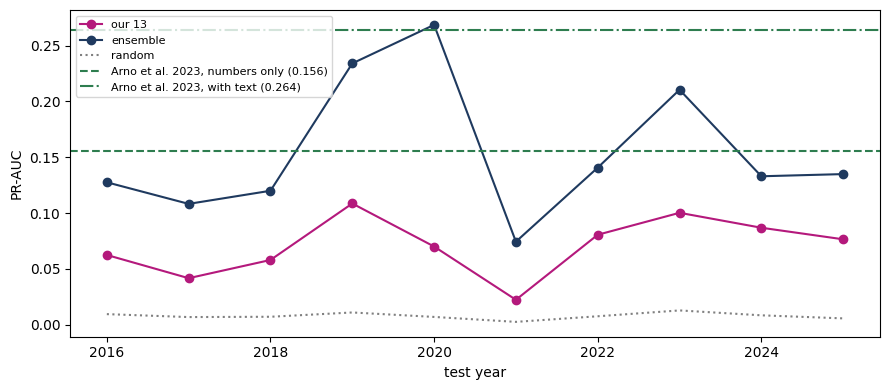

bankruptcies        random PR-AUC          PR-AUC        times random  \
model     ensemble our 13      ensemble our 13 ensemble our 13     ensemble   
year                                                                          
2016         234.0  234.0         0.010  0.010    0.128  0.062       13.407   
2017         166.0  166.0         0.007  0.007    0.108  0.042       15.732   
2018         167.0  167.0         0.007  0.007    0.120  0.058       16.775   
2019         250.0  250.0         0.011  0.011    0.234  0.109       21.283   
2020         155.0  155.0         0.007  0.007    0.268  0.070       38.330   
2021          64.0   64.0         0.003  0.003    0.074  0.022       28.809   
2022         197.0  197.0         0.008  0.008    0.141  0.081       18.510   
2023         313.0  313.0         0.013  0.013    0.210  0.100       16.398   
2024         192.0  192.0         0.008  0.008    0.133  0.087       15.743   
2025          95.0   95.0         0.006  0.006    0.135  0.076       23.619   

               ROC-AUC         
model  our 13 ensemble our 13  
year                           
2016    6.565    0.784  0.690  
2017    6.059    0.892  0.814  
2018    8.111    0.933  0.880  
2019    9.875    0.919  0.886  
2020    9.998    0.946  0.878  
2021    8.658    0.888  0.842  
2022   10.603    0.880  0.862  
2023    7.812    0.889  0.870  
2024   10.285    0.932  0.929  
2025   13.396    0.918  0.902

In [8]:
best_name = model_table.xs("2016-2021, all reports", level="window")["PR-AUC"].idxmax()
best_scores = model_scores[best_name]
by_year = pd.DataFrame([{**summary(set_scores["our 13"], "our 13", years=[y]), "year": y} for y in TEST_YEARS]
                       + [{**summary(best_scores, best_name, years=[y]), "year": y} for y in TEST_YEARS])
by_year = by_year.pivot(index="year", columns="model", values=["bankruptcies", "random PR-AUC", "PR-AUC", "times random", "ROC-AUC"])
print("best model:", best_name)

fig, ax = plt.subplots(figsize=(9, 4))
for name, color in [("our 13", "#B4197C"), (best_name, "#1F3A5F")]:
    ax.plot(by_year.index, by_year[("PR-AUC", name)], marker="o", color=color, label=name)
ax.plot(by_year.index, by_year[("random PR-AUC", "our 13")], linestyle=":", color="grey", label="random")
ax.axhline(0.156, color="#2E7D4F", linestyle="--", label="Arno et al. 2023, numbers only (0.156)")
ax.axhline(0.264, color="#2E7D4F", linestyle="-.", label="Arno et al. 2023, with text (0.264)")
ax.set_xlabel("test year")
ax.set_ylabel("PR-AUC")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("pr_auc_by_year.png", dpi=200)
plt.show()
by_year.round(3)

## 5. What the Best Model Looks At

SHAP from an XGBoost model trained on reports filed up to 2023 (their answers are known by the end of 2024), on the 2025 reports. The share by group says where the signal comes from.

In [9]:
fit, test = df[df["year"] <= 2023], df[df["year"] == 2025]
last_model = xgb_model(PARAMS).fit(fit[everything_features], fit["Bankruptcy"])
contributions = last_model.get_booster().predict(DMatrix(test[everything_features]), pred_contribs=True)[:, :-1]
mean_abs = pd.Series(np.abs(contributions).mean(axis=0), index=everything_features).sort_values(ascending=False)
group_of = {f: g for g, fs in groups.items() for f in fs}
shap_table = pd.DataFrame({"share": mean_abs / mean_abs.sum(), "group": [group_of[f] for f in mean_abs.index]})
print(shap_table.groupby("group")["share"].sum().sort_values(ascending=False).round(3))
shap_table.head(25).round(4)

group
accounting ratios      0.431
warning signs          0.195
trends and history     0.133
8 variables            0.130
industry comparison    0.074
filing behavior        0.037
Name: share, dtype: float32


,share,group
going_concern_in_report,0.0270,warning signs
net_income_to_assets,0.0264,accounting ratios
total_liabilities,0.0227,8 variables
losses_in_last_4,0.0226,trends and history
operating_income,0.0215,8 variables
days_since_late_filing_notice,0.0196,warning signs
net_income,0.0195,8 variables
current_assets,0.0192,8 variables
retained_earnings_to_assets,0.0189,accounting ratios
liabilities_to_assets,0.0175,accounting ratios


## 6. Round 2: Better Settings and a Tuned Ensemble

Round 1 showed two things: HistGradientBoosting with slow learning (600 small steps) beat XGBoost with the settings Optuna picked on 2009 to 2012 (200 big steps), and the warning signs add the most. So round 2:

1. **Stricter and new phrases** in the warning signs: "identified a material weakness" (the plain phrase also finds "we did not identify any material weakness"), "not in compliance with" + "covenants", "notice of default", "debtor-in-possession", "cease operations" and "wind down".
2. **Tuning on a bigger window**: train on reports filed 2009 to 2012, check on 2013 and 2014 (answers known by the end of 2015, before the first test year), with slower learning rates allowed. Both XGBoost and HistGradientBoosting are tuned.
3. **The ensemble** of the tuned XGBoost and the tuned HistGradientBoosting, 3 seeds each, averaged by rank within the year.

In [5]:
everything_features = sum(groups.values(), [])
print(len(everything_features), "features, warning signs:", len(groups["warning signs"]))
tune_fit, tune_val = df[df["year"] <= 2012], df[df["year"].isin([2013, 2014])]


def make_xgb_params(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 300, 1500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 0.8),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 0, 10),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1, 100, log=True),
    }


def make_hgb_params(trial):
    return {
        "max_iter": trial.suggest_int("max_iter", 300, 1500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.08, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 8, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 20, 400, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 50, log=True),
        "max_features": trial.suggest_float("max_features", 0.2, 1.0),
        "positive_weight": trial.suggest_float("positive_weight", 1, 100, log=True),
    }


def hgb_from(params, seed=42):
    params = dict(params)
    weight = params.pop("positive_weight")
    return HistGradientBoostingClassifier(**params, class_weight={0: 1, 1: weight}, random_state=seed)


def tuned(make_params, build, n_trials):
    def objective(trial):
        model = build(make_params(trial)).fit(tune_fit[everything_features], tune_fit["Bankruptcy"])
        return average_precision_score(tune_val["Bankruptcy"], model.predict_proba(tune_val[everything_features])[:, 1])
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials)
    return study.best_params, study.best_value


start = time.time()
XGB_PARAMS, xgb_value = tuned(make_xgb_params, xgb_model, 40)
HGB_PARAMS, hgb_value = tuned(make_hgb_params, hgb_from, 30)
print("took", round((time.time() - start) / 60, 1), "minutes")
print("validation PR-AUC (2013-2014)  XGBoost:", round(xgb_value, 3), " HistGradientBoosting:", round(hgb_value, 3))
print(XGB_PARAMS)
print(HGB_PARAMS)

140 features, warning signs: 57


took 145.6 minutes
validation PR-AUC (2013-2014)  XGBoost: 0.192  HistGradientBoosting: 0.153
{'n_estimators': 1400, 'learning_rate': 0.030435151413863663, 'max_depth': 8, 'min_child_weight': 2.649496317267566, 'subsample': 0.8794818753946948, 'colsample_bytree': 0.6094118179765666, 'gamma': 0.43319316787210643, 'reg_alpha': 0.0015962113607134825, 'reg_lambda': 5.696284007633162, 'max_delta_step': 1, 'scale_pos_weight': 6.61283698692129}
{'max_iter': 700, 'learning_rate': 0.016936100237959675, 'max_leaf_nodes': 16, 'min_samples_leaf': 79, 'l2_regularization': 0.0034571514874312793, 'max_features': 0.6026182928242957, 'positive_weight': 14.663418530536454}


In [6]:
def rank_in_year(scores):
    return scores.groupby("year")["score"].rank(pct=True)


start = time.time()
round2 = {"our 13 (round 1 settings)": walk_forward(our_13),
          "XGBoost tuned, 3 seeds": walk_forward(everything_features, lambda seed: xgb_model(XGB_PARAMS, seed), seeds=(42, 7, 2024)),
          "HistGradientBoosting tuned, 3 seeds": walk_forward(everything_features, lambda seed: hgb_from(HGB_PARAMS, seed), seeds=(42, 7, 2024))}
ensemble2 = round2["XGBoost tuned, 3 seeds"][["year"]].copy()
ensemble2["score"] = (rank_in_year(round2["XGBoost tuned, 3 seeds"]) + rank_in_year(round2["HistGradientBoosting tuned, 3 seeds"])) / 2
round2["round 2 ensemble"] = ensemble2
print("took", round((time.time() - start) / 60, 1), "minutes")
round2_table = window_table(round2, against_name="our 13 (round 1 settings)")
round2_table[["reports", "bankruptcies", "ROC-AUC", "PR-AUC", "times random", "caught in top 5%",
              "PR-AUC low (5%)", "PR-AUC high (95%)", "change", "change low (5%)", "change high (95%)"]].round(3)

took 10.6 minutes


reports  \
window                                  model                                          
2016-2021, 10-K only (Arno et al. test) our 13 (round 1 settings)              34753   
                                        XGBoost tuned, 3 seeds                 34753   
                                        HistGradientBoosting tuned, 3 seeds    34753   
                                        round 2 ensemble                       34753   
2016-2021, all reports                  our 13 (round 1 settings)             141743   
                                        XGBoost tuned, 3 seeds                141743   
                                        HistGradientBoosting tuned, 3 seeds   141743   
                                        round 2 ensemble                      141743   
2023-2025, all reports (our years)      our 13 (round 1 settings)              63767   
                                        XGBoost tuned, 3 seeds                 63767   
                                        HistGradientBoosting tuned, 3 seeds    63767   
                                        round 2 ensemble                       63767   

                                                                             bankruptcies  \
window                                  model                                               
2016-2021, 10-K only (Arno et al. test) our 13 (round 1 settings)                     268   
                                        XGBoost tuned, 3 seeds                        268   
                                        HistGradientBoosting tuned, 3 seeds           268   
                                        round 2 ensemble                              268   
2016-2021, all reports                  our 13 (round 1 settings)                    1036   
                                        XGBoost tuned, 3 seeds                       1036   
                                        HistGradientBoosting tuned, 3 seeds          1036   
                                        round 2 ensemble                             1036   
2023-2025, all reports (our years)      our 13 (round 1 settings)                     600   
                                        XGBoost tuned, 3 seeds                        600   
                                        HistGradientBoosting tuned, 3 seeds           600   
                                        round 2 ensemble                              600   

                                                                             ROC-AUC  \
window                                  model                                          
2016-2021, 10-K only (Arno et al. test) our 13 (round 1 settings)              0.818   
                                        XGBoost tuned, 3 seeds                 0.869   
                                        HistGradientBoosting tuned, 3 seeds    0.865   
                                        round 2 ensemble                       0.867   
2016-2021, all reports                  our 13 (round 1 settings)              0.837   
                                        XGBoost tuned, 3 seeds                 0.887   
                                        HistGradientBoosting tuned, 3 seeds    0.882   
                                        round 2 ensemble                       0.887   
2023-2025, all reports (our years)      our 13 (round 1 settings)              0.892   
                                        XGBoost tuned, 3 seeds                 0.914   
                                        HistGradientBoosting tuned, 3 seeds    0.915   
                                        round 2 ensemble                       0.917   

                                                                             PR-AUC  \
window                                  model                                         
2016-2021, 10-K only (Arno et al. test) our 13 (round 1 settings)             0.078   
                                        XGBoost

## 7. Against the Best Published Result

The closest published study, Arno et al. (2023), on the same test years (2016 to 2021) and the same kind of reports (10-K): ROC-AUC 0.936 and PR-AUC 0.156 with numbers only, 0.948 and 0.264 with the text of the filings (TF-IDF on the MD&A). Their positive share in the test was 0.67%. The fairest comparison across tests is "times random" (PR-AUC divided by the share of 1s).

In [7]:
arno = pd.DataFrame([{"model": "Arno et al. (2023), numbers only", "ROC-AUC": 0.936, "PR-AUC": 0.156, "random PR-AUC": 0.0067},
                     {"model": "Arno et al. (2023), numbers + text", "ROC-AUC": 0.948, "PR-AUC": 0.264, "random PR-AUC": 0.0067}])
arno["times random"] = arno["PR-AUC"] / arno["random PR-AUC"]
ours = round2_table.xs("2016-2021, 10-K only (Arno et al. test)", level="window").reset_index()
ours = ours[["model", "ROC-AUC", "PR-AUC", "random PR-AUC", "times random"]]
pd.concat([arno, ours]).set_index("model").round(3)

,ROC-AUC,PR-AUC,random PR-AUC,times random
model,,,,
"Arno et al. (2023), numbers only",0.936,0.156,0.007,23.284
"Arno et al. (2023), numbers + text",0.948,0.264,0.007,39.403
our 13 (round 1 settings),0.818,0.078,0.008,10.173
"XGBoost tuned, 3 seeds",0.869,0.161,0.008,20.841
"HistGradientBoosting tuned, 3 seeds",0.865,0.147,0.008,19.004
round 2 ensemble,0.867,0.134,0.008,17.433
